In [ ]:
# ============================================================
# CHUNK 1 — INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install opencv-python-headless pandas numpy tqdm pillow

In [ ]:
# ============================================================
# CHUNK 2 — IMPORT LIBRARIES
# ============================================================

import os
import gc
import cv2
import json
import math
import time
import shutil
import hashlib
import zipfile
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CHUNK 3 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
# ============================================================
# CHUNK 4 — SET ECHONET-DYNAMIC DATASET PATH
# ============================================================

DATASET_ROOT = "/content/drive/MyDrive/EchoNet-Dynamic"

DATASET_ROOT = os.path.abspath(DATASET_ROOT)

print("Dataset root:")
print(DATASET_ROOT)

if not os.path.exists(DATASET_ROOT):
    raise FileNotFoundError(
        f"\nDataset not found:\n{DATASET_ROOT}\n\n"
        "Please correct DATASET_ROOT in this cell."
    )

print("\nDataset directory exists.")

Dataset root:
/content/drive/MyDrive/EchoNet-Dynamic

Dataset directory exists.


In [ ]:
# ============================================================
# CHUNK 5 — INSPECT DATASET STRUCTURE
# ============================================================

print("=" * 70)
print("ECHONET-DYNAMIC DATASET STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(DATASET_ROOT):

    relative = os.path.relpath(root, DATASET_ROOT)

    depth = 0 if relative == "." else relative.count(os.sep) + 1

    if depth > 2:
        continue

    indent = "    " * depth

    folder_name = os.path.basename(root)

    print(f"{indent}{folder_name}/")

    for file in sorted(files)[:15]:

        print(f"{indent}    {file}")

    if len(files) > 15:

        print(
            f"{indent}    ... "
            f"{len(files) - 15} more files"
        )

ECHONET-DYNAMIC DATASET STRUCTURE
EchoNet-Dynamic/
    FileList.csv
    VolumeTracings.csv
    Videos/
        .DS_Store
        0X100009310A3BD7FC.avi
        0X1002E8FBACD08477.avi
        0X1005D03EED19C65B.avi
        0X10075961BC11C88E.avi
        0X10094BA0A028EAC3.avi
        0X100CF05D141FF143.avi
        0X100E3B8D3280BEC5.avi
        0X100E491B3CD58DE2.avi
        0X100F044876B98F90.avi
        0X101026B90DAE7E95.avi
        0X1012703CDC1436FE.avi
        0X1013E8A4864781B.avi
        0X1018521A3BC5CDBA.avi
        0X101C388397F66EDB.avi
        ... 10026 more files


In [ ]:
# ============================================================
# CHUNK 6 — FIND ALL ECHOCARDIOGRAM VIDEOS
# ============================================================

VIDEO_EXTENSIONS = {
    ".avi",
    ".mp4",
    ".mov",
    ".mkv",
    ".mpeg",
    ".mpg",
    ".wmv"
}

video_files = []

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        extension = Path(filename).suffix.lower()

        if extension in VIDEO_EXTENSIONS:

            video_files.append(
                os.path.join(root, filename)
            )

video_files = sorted(video_files)

print(
    f"Total videos found: {len(video_files):,}"
)

if len(video_files) == 0:

    raise RuntimeError(
        "No video files were found."
    )

print("\nFirst 10 videos:")

for video in video_files[:10]:

    print(video)

Total videos found: 10,040

First 10 videos:
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X100009310A3BD7FC.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X1002E8FBACD08477.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X1005D03EED19C65B.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X10075961BC11C88E.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X10094BA0A028EAC3.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X100CF05D141FF143.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X100E3B8D3280BEC5.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X100E491B3CD58DE2.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X100F044876B98F90.avi
/content/drive/MyDrive/EchoNet-Dynamic/Videos/0X101026B90DAE7E95.avi


In [ ]:
# ============================================================
# CHUNK 7 — FIND ALL CSV FILES
# ============================================================

csv_files = []

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        if filename.lower().endswith(".csv"):

            csv_files.append(
                os.path.join(root, filename)
            )

csv_files = sorted(csv_files)

print(
    f"CSV files found: {len(csv_files)}"
)

for csv_file in csv_files:

    print(
        os.path.relpath(
            csv_file,
            DATASET_ROOT
        )
    )

CSV files found: 2
FileList.csv
VolumeTracings.csv


In [ ]:
# ============================================================
# CHUNK 7 — FIND ALL CSV FILES
# ============================================================

csv_files = []

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        if filename.lower().endswith(".csv"):

            csv_files.append(
                os.path.join(root, filename)
            )

csv_files = sorted(csv_files)

print(
    f"CSV files found: {len(csv_files)}"
)

for csv_file in csv_files:

    print(
        os.path.relpath(
            csv_file,
            DATASET_ROOT
        )
    )

CSV files found: 2
FileList.csv
VolumeTracings.csv


In [ ]:
# ============================================================
# CHUNK 9 — FIND FILELIST.CSV
# ============================================================

filelist_candidates = [

    path

    for path in csv_files

    if os.path.basename(path).lower()
    == "filelist.csv"
]

if not filelist_candidates:

    raise FileNotFoundError(
        "FileList.csv was not found."
    )

FILELIST_PATH = filelist_candidates[0]

print("Using:")
print(FILELIST_PATH)

filelist_df = pd.read_csv(
    FILELIST_PATH
)

print("\nShape:")
print(filelist_df.shape)

print("\nColumns:")
print(filelist_df.columns.tolist())

display(
    filelist_df.head()
)

Using:
/content/drive/MyDrive/EchoNet-Dynamic/FileList.csv

Shape:
(10030, 9)

Columns:
['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


In [ ]:
# ============================================================
# CHUNK 10 — INSPECT ORIGINAL LABELS
# ============================================================

print("=" * 70)
print("ECHONET LABEL / TARGET INFORMATION")
print("=" * 70)

for column in filelist_df.columns:

    print(
        f"{column:25s} "
        f"| dtype={filelist_df[column].dtype} "
        f"| missing={filelist_df[column].isna().sum()}"
    )

ECHONET LABEL / TARGET INFORMATION
FileName                  | dtype=object | missing=0
EF                        | dtype=float64 | missing=0
ESV                       | dtype=float64 | missing=0
EDV                       | dtype=float64 | missing=0
FrameHeight               | dtype=int64 | missing=0
FrameWidth                | dtype=int64 | missing=0
FPS                       | dtype=int64 | missing=0
NumberOfFrames            | dtype=int64 | missing=0
Split                     | dtype=object | missing=0


In [ ]:
# ============================================================
# CHUNK 11 — IDENTIFY VIDEO NAME COLUMN
# ============================================================

possible_video_columns = [
    "FileName",
    "Filename",
    "file_name",
    "filename",
    "Video",
    "video",
    "VideoName",
    "video_name"
]

VIDEO_COLUMN = None

for column in possible_video_columns:

    if column in filelist_df.columns:

        VIDEO_COLUMN = column
        break

if VIDEO_COLUMN is None:

    raise ValueError(
        "Could not automatically identify "
        "the video filename column.\n\n"
        f"Available columns:\n"
        f"{filelist_df.columns.tolist()}"
    )

print(
    "Video filename column:",
    VIDEO_COLUMN
)

Video filename column: FileName


In [ ]:
# ============================================================
# CHUNK 12 — BUILD VIDEO LOOKUP TABLE
# ============================================================

video_lookup = {}

for path in video_files:

    filename = os.path.basename(path)

    stem = os.path.splitext(
        filename
    )[0]

    video_lookup[filename] = path
    video_lookup[stem] = path

print(
    "Video lookup entries:",
    len(video_lookup)
)

Video lookup entries: 20080


In [ ]:
# ============================================================
# CHUNK 13 — MATCH METADATA TO ACTUAL VIDEOS
# ============================================================

matched_paths = []
unmatched_rows = []

for index, row in filelist_df.iterrows():

    value = str(
        row[VIDEO_COLUMN]
    ).strip()

    basename = os.path.basename(value)

    stem = os.path.splitext(
        basename
    )[0]

    path = None

    if basename in video_lookup:

        path = video_lookup[basename]

    elif stem in video_lookup:

        path = video_lookup[stem]

    if path is None:

        unmatched_rows.append(index)

        matched_paths.append(None)

    else:

        matched_paths.append(path)

filelist_df = filelist_df.copy()

filelist_df["source_video_path"] = matched_paths

matched_count = (
    filelist_df["source_video_path"]
    .notna()
    .sum()
)

print(
    f"Matched videos: {matched_count:,}"
)

print(
    f"Unmatched metadata rows: "
    f"{len(unmatched_rows):,}"
)

if len(unmatched_rows) > 0:

    print(
        "\nWARNING: Some metadata rows "
        "could not be matched."
    )

Matched videos: 10,030
Unmatched metadata rows: 0


In [ ]:
# ============================================================
# CHUNK 14 — DATASET VALIDATION
# ============================================================

if matched_count == 0:

    raise RuntimeError(
        "No metadata rows matched videos."
    )

print("=" * 70)
print("DATASET VALIDATION")
print("=" * 70)

print(
    "Metadata rows:",
    len(filelist_df)
)

print(
    "Videos found:",
    len(video_files)
)

print(
    "Matched rows:",
    matched_count
)

print(
    "Unmatched rows:",
    len(unmatched_rows)
)

if "Split" in filelist_df.columns:

    print(
        "\nOriginal dataset split:"
    )

    print(
        filelist_df["Split"]
        .value_counts()
    )

DATASET VALIDATION
Metadata rows: 10030
Videos found: 10040
Matched rows: 10030
Unmatched rows: 0

Original dataset split:
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64


In [ ]:
# ============================================================
# CHUNK 14 — DATASET VALIDATION
# ============================================================

if matched_count == 0:

    raise RuntimeError(
        "No metadata rows matched videos."
    )

print("=" * 70)
print("DATASET VALIDATION")
print("=" * 70)

print(
    "Metadata rows:",
    len(filelist_df)
)

print(
    "Videos found:",
    len(video_files)
)

print(
    "Matched rows:",
    matched_count
)

print(
    "Unmatched rows:",
    len(unmatched_rows)
)

if "Split" in filelist_df.columns:

    print(
        "\nOriginal dataset split:"
    )

    print(
        filelist_df["Split"]
        .value_counts()
    )

DATASET VALIDATION
Metadata rows: 10030
Videos found: 10040
Matched rows: 10030
Unmatched rows: 0

Original dataset split:
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64


In [ ]:
# ============================================================
# CHUNK 16 — CREATE TEMPORARY OUTPUT DIRECTORIES
# ============================================================

WORK_ROOT = "/content/EchoNet_Frame_Utility"

FRAME_DIR = os.path.join(
    WORK_ROOT,
    "frames"
)

PARTS_DIR = os.path.join(
    "/content",
    "EchoNet_Download_Parts"
)

LOG_DIR = os.path.join(
    WORK_ROOT,
    "logs"
)

os.makedirs(
    FRAME_DIR,
    exist_ok=True
)

os.makedirs(
    PARTS_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

print("Work directory:")
print(WORK_ROOT)

print("\nDownload directory:")
print(PARTS_DIR)

Work directory:
/content/EchoNet_Frame_Utility

Download directory:
/content/EchoNet_Download_Parts


In [ ]:
# ============================================================
# CHUNK 17 — CHECK COLAB STORAGE
# ============================================================

def get_free_space_gb(
    path="/content"
):

    total, used, free = (
        shutil.disk_usage(path)
    )

    return (
        total / (1024**3),
        used / (1024**3),
        free / (1024**3)
    )

total_gb, used_gb, free_gb = (
    get_free_space_gb()
)

print(
    f"Total storage: {total_gb:.2f} GB"
)

print(
    f"Used storage : {used_gb:.2f} GB"
)

print(
    f"Free storage : {free_gb:.2f} GB"
)

Total storage: 112.64 GB
Used storage : 42.36 GB
Free storage : 70.26 GB


In [ ]:
# ============================================================
# CHUNK 18 — COMPLETE FRAME EXTRACTION UTILITY
# ============================================================

def extract_video_to_frames(
    video_path,
    output_root,
    metadata_row
):

    video_filename = os.path.basename(
        video_path
    )

    video_id = os.path.splitext(
        video_filename
    )[0]

    video_output_dir = os.path.join(
        output_root,
        video_id
    )

    os.makedirs(
        video_output_dir,
        exist_ok=True
    )

    cap = cv2.VideoCapture(
        video_path
    )

    if not cap.isOpened():

        return {
            "success": False,
            "video_id": video_id,
            "frames": 0,
            "error": "Unable to open video",
            "records": []
        }

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    width = int(
        cap.get(
            cv2.CAP_PROP_FRAME_WIDTH
        )
    )

    height = int(
        cap.get(
            cv2.CAP_PROP_FRAME_HEIGHT
        )
    )

    frame_count = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if fps <= 0:

        fps = None

    records = []

    frame_index = 0

    while True:

        success, frame = cap.read()

        if not success:
            break

        frame_filename = (
            f"{video_id}_"
            f"frame_{frame_index:06d}.png"
        )

        frame_path = os.path.join(
            video_output_dir,
            frame_filename
        )

        # ----------------------------------------------------
        # Save decoded frame as PNG.
        # No resize.
        # No crop.
        # No normalization.
        # ----------------------------------------------------

        saved = cv2.imwrite(
            frame_path,
            frame,
            [
                cv2.IMWRITE_PNG_COMPRESSION,
                3
            ]
        )

        if not saved:

            cap.release()

            return {
                "success": False,
                "video_id": video_id,
                "frames": frame_index,
                "error": (
                    "Failed to save frame"
                ),
                "records": records
            }

        timestamp = (
            frame_index / fps
            if fps is not None
            else None
        )

        record = {

            "video_id":
                video_id,

            "source_video":
                video_filename,

            "source_video_path":
                video_path,

            "frame_index":
                frame_index,

            "timestamp_seconds":
                timestamp,

            "fps":
                fps,

            "width":
                width,

            "height":
                height,

            "frame_count_reported":
                frame_count,

            "frame_filename":
                frame_filename,

            "relative_frame_path":
                os.path.join(
                    video_id,
                    frame_filename
                )
        }

        # ----------------------------------------------------
        # Preserve EVERY original metadata field
        # ----------------------------------------------------

        for column in metadata_row.index:

            key = str(column)

            if key not in record:

                value = metadata_row[column]

                if pd.isna(value):

                    value = None

                record[
                    f"label_{key}"
                ] = value

        records.append(
            record
        )

        frame_index += 1

    cap.release()

    return {

        "success": True,

        "video_id":
            video_id,

        "frames":
            frame_index,

        "error":
            "",

        "records":
            records,

        "fps":
            fps,

        "width":
            width,

        "height":
            height,

        "reported_frame_count":
            frame_count
    }

In [ ]:
# ============================================================
# CHUNK 19 — TEST EXTRACTION ON ONE VIDEO
# ============================================================

# Define the test video using the first available video path
if 'video_files' in globals() and len(video_files) > 0:
    test_video = video_files[0]
else:
    raise RuntimeError("No video files available to test with.")

# Remove previous test frames
TEST_DIR = "/content/EchoNet_Test"

if os.path.exists(TEST_DIR):
    shutil.rmtree(TEST_DIR)

os.makedirs(TEST_DIR, exist_ok=True)

test_row = filelist_df[
    filelist_df["source_video_path"]
    == test_video
]

if len(test_row) == 0:
    raise RuntimeError(
        "Could not find metadata for test video."
    )

test_row = test_row.iloc[0]

test_result = extract_video_to_frames(
    test_video,
    TEST_DIR,
    test_row
)

print(
    "Success:",
    test_result["success"]
)

print(
    "Frames extracted:",
    test_result["frames"]
)

print(
    "FPS:",
    test_result.get("fps")
)

print(
    "Resolution:",
    test_result.get("width"),
    "x",
    test_result.get("height")
)

Success: True
Frames extracted: 174
FPS: 50.0
Resolution: 112 x 112


PNG frames found: 174

First frame:
/content/EchoNet_Test/0X100009310A3BD7FC/0X100009310A3BD7FC_frame_000000.png

PNG dimensions: (112, 112)
PNG mode: RGB


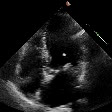

In [ ]:
# ============================================================
# CHUNK 20 — VERIFY TEST FRAMES
# ============================================================

test_pngs = []

for root, dirs, files in os.walk(
    TEST_DIR
):

    for file in files:

        if file.lower().endswith(
            ".png"
        ):

            test_pngs.append(
                os.path.join(
                    root,
                    file
                )
            )

test_pngs = sorted(
    test_pngs
)

print(
    "PNG frames found:",
    len(test_pngs)
)

if len(test_pngs) > 0:

    print(
        "\nFirst frame:"
    )

    print(
        test_pngs[0]
    )

    image = Image.open(
        test_pngs[0]
    )

    print(
        "\nPNG dimensions:",
        image.size
    )

    print(
        "PNG mode:",
        image.mode
    )

    display(
        image
    )

In [ ]:
# ============================================================
# CHUNK 21 — VERIFY FRAME ORDER
# ============================================================

test_video_id = os.path.splitext(
    os.path.basename(test_video)
)[0]

test_video_dir = os.path.join(
    TEST_DIR,
    test_video_id
)

test_frames = sorted(
    [
        f
        for f in os.listdir(
            test_video_dir
        )
        if f.endswith(".png")
    ]
)

print(
    "First 10 frames:"
)

for frame in test_frames[:10]:

    print(frame)

print(
    "\nLast 5 frames:"
)

for frame in test_frames[-5:]:

    print(frame)

First 10 frames:
0X100009310A3BD7FC_frame_000000.png
0X100009310A3BD7FC_frame_000001.png
0X100009310A3BD7FC_frame_000002.png
0X100009310A3BD7FC_frame_000003.png
0X100009310A3BD7FC_frame_000004.png
0X100009310A3BD7FC_frame_000005.png
0X100009310A3BD7FC_frame_000006.png
0X100009310A3BD7FC_frame_000007.png
0X100009310A3BD7FC_frame_000008.png
0X100009310A3BD7FC_frame_000009.png

Last 5 frames:
0X100009310A3BD7FC_frame_000169.png
0X100009310A3BD7FC_frame_000170.png
0X100009310A3BD7FC_frame_000171.png
0X100009310A3BD7FC_frame_000172.png
0X100009310A3BD7FC_frame_000173.png


In [ ]:
# ============================================================
# CHUNK 22 — REMOVE TEST DATA
# ============================================================

if os.path.exists(TEST_DIR):

    shutil.rmtree(
        TEST_DIR
    )

print(
    "Test data removed."
)

print(
    "Full processing can now begin."
)

Test data removed.
Full processing can now begin.


In [ ]:
# ============================================================
# CHUNK 23 — BATCH CONFIGURATION
# ============================================================

VIDEOS_PER_BATCH = 20

# Safety margin for Colab storage.
MIN_FREE_SPACE_GB = 5.0

print(
    "Videos per batch:",
    VIDEOS_PER_BATCH
)

print(
    "Minimum desired free storage:",
    MIN_FREE_SPACE_GB,
    "GB"
)

Videos per batch: 20
Minimum desired free storage: 5.0 GB


In [ ]:
# ============================================================
# CHUNK 24 — FULL DATASET PROCESSING UTILITY
# ============================================================

def process_batch(
    batch_number,
    batch_df
):

    print("\n")
    print("=" * 80)
    print(
        f"PROCESSING BATCH {batch_number}"
    )
    print(
        f"Videos: {len(batch_df)}"
    )
    print("=" * 80)

    # --------------------------------------------------------
    # Clean temporary frame directory
    # --------------------------------------------------------

    if os.path.exists(
        FRAME_DIR
    ):

        shutil.rmtree(
            FRAME_DIR
        )

    os.makedirs(
        FRAME_DIR,
        exist_ok=True
    )

    batch_records = []

    errors = []

    # --------------------------------------------------------
    # Process each video
    # --------------------------------------------------------

    for _, row in tqdm(
        batch_df.iterrows(),
        total=len(batch_df),
        desc=f"Batch {batch_number}"
    ):

        video_path = row[
            "source_video_path"
        ]

        result = extract_video_to_frames(
            video_path,
            FRAME_DIR,
            row
        )

        if result["success"]:

            batch_records.extend(
                result["records"]
            )

        else:

            errors.append({

                "video":
                    video_path,

                "video_id":
                    result["video_id"],

                "error":
                    result["error"]
            })

    # --------------------------------------------------------
    # Save frame metadata
    # --------------------------------------------------------

    batch_metadata_df = pd.DataFrame(
        batch_records
    )

    metadata_filename = (
        f"EchoNet_Frame_Metadata_"
        f"Batch_{batch_number:04d}.csv"
    )

    metadata_path = os.path.join(
        PARTS_DIR,
        metadata_filename
    )

    batch_metadata_df.to_csv(
        metadata_path,
        index=False
    )

    # --------------------------------------------------------
    # Save errors
    # --------------------------------------------------------

    error_filename = (
        f"EchoNet_Errors_"
        f"Batch_{batch_number:04d}.csv"
    )

    error_path = os.path.join(
        PARTS_DIR,
        error_filename
    )

    pd.DataFrame(
        errors
    ).to_csv(
        error_path,
        index=False
    )

    # --------------------------------------------------------
    # Create ZIP
    # --------------------------------------------------------

    archive_base = os.path.join(
        PARTS_DIR,
        f"EchoNet_Frame_Dataset_"
        f"Part_{batch_number:04d}"
    )

    print(
        "\nCreating ZIP archive..."
    )

    shutil.make_archive(
        archive_base,
        "zip",
        FRAME_DIR
    )

    archive_path = (
        archive_base + ".zip"
    )

    archive_size_gb = (
        os.path.getsize(
            archive_path
        )
        / (1024 ** 3)
    )

    print(
        "\nArchive created:"
    )

    print(
        archive_path
    )

    print(
        f"Archive size: "
        f"{archive_size_gb:.2f} GB"
    )

    # --------------------------------------------------------
    # Delete temporary PNG files
    # --------------------------------------------------------

    shutil.rmtree(
        FRAME_DIR
    )

    gc.collect()

    return {

        "batch_number":
            batch_number,

        "videos":
            len(batch_df),

        "frames":
            len(batch_records),

        "errors":
            len(errors),

        "archive":
            archive_path,

        "metadata":
            metadata_path,

        "archive_size_gb":
            archive_size_gb
    }

In [ ]:
# ============================================================
# CHUNK 25 — RUN COMPLETE ECHONET FRAME CONVERSION
# ============================================================

# Only rows with an actual video
# are processed.

processing_df = filelist_df[
    filelist_df["source_video_path"]
    .notna()
].copy()

processing_df = processing_df.reset_index(
    drop=True
)

total_videos = len(
    processing_df
)

print(
    f"Videos to process: "
    f"{total_videos:,}"
)

num_batches = math.ceil(
    total_videos /
    VIDEOS_PER_BATCH
)

print(
    f"Number of batches: "
    f"{num_batches}"
)

batch_results = []

for batch_number in range(
    1,
    num_batches + 1
):

    # --------------------------------------------------------
    # Check whether this batch already exists
    # --------------------------------------------------------

    archive_path = os.path.join(
        PARTS_DIR,
        f"EchoNet_Frame_Dataset_"
        f"Part_{batch_number:04d}.zip"
    )

    if os.path.exists(
        archive_path
    ):

        print(
            f"\nBatch {batch_number} "
            f"already exists."
        )

        print(
            "Skipping it."
        )

        continue

    # --------------------------------------------------------
    # Select batch
    # --------------------------------------------------------

    start = (
        (batch_number - 1)
        * VIDEOS_PER_BATCH
    )

    end = min(
        start + VIDEOS_PER_BATCH,
        total_videos
    )

    batch_df = processing_df.iloc[
        start:end
    ]

    # --------------------------------------------------------
    # Process
    # --------------------------------------------------------

    result = process_batch(
        batch_number,
        batch_df
    )

    batch_results.append(
        result
    )

    # --------------------------------------------------------
    # Check storage
    # --------------------------------------------------------

    total_gb, used_gb, free_gb = (
        get_free_space_gb()
    )

    print(
        f"\nRemaining Colab storage: "
        f"{free_gb:.2f} GB"
    )

    if free_gb < MIN_FREE_SPACE_GB:

        print(
            "\nSTOPPING SAFELY."
        )

        print(
            "Colab storage is getting low."
        )

        break

print(
    "\nDataset processing loop finished."
)

Videos to process: 10,030
Number of batches: 502


PROCESSING BATCH 1
Videos: 20


Batch 1:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/content/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0001.zip
Archive size: 0.04 GB

Remaining Colab storage: 70.20 GB


PROCESSING BATCH 2
Videos: 20


Batch 2:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/content/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0002.zip
Archive size: 0.04 GB

Remaining Colab storage: 70.14 GB


PROCESSING BATCH 3
Videos: 20


Batch 3:   0%|          | 0/20 [00:00<?, ?it/s]

... (995 outputs left out)

Batch 501:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/content/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0501.zip
Archive size: 0.04 GB

Remaining Colab storage: 42.50 GB


PROCESSING BATCH 502
Videos: 10


Batch 502:   0%|          | 0/10 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/content/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0502.zip
Archive size: 0.02 GB

Remaining Colab storage: 42.47 GB

Dataset processing loop finished.


In [ ]:
# ============================================================
# CHUNK 26 — BUILD MASTER FRAME METADATA
# ============================================================

metadata_files = sorted([

    os.path.join(
        PARTS_DIR,
        filename
    )

    for filename in os.listdir(
        PARTS_DIR
    )

    if (
        filename.startswith(
            "EchoNet_Frame_Metadata_Batch_"
        )
        and filename.endswith(".csv")
    )

])

print(
    "Metadata batch files:",
    len(metadata_files)
)

master_metadata_path = os.path.join(
    PARTS_DIR,
    "EchoNet_Frame_Metadata_MASTER.csv"
)

if metadata_files:

    frames = []

    for file in tqdm(
        metadata_files,
        desc="Combining metadata"
    ):

        frames.append(
            pd.read_csv(file)
        )

    master_metadata = pd.concat(
        frames,
        ignore_index=True
    )

    master_metadata.to_csv(
        master_metadata_path,
        index=False
    )

    print(
        "\nMaster metadata saved:"
    )

    print(
        master_metadata_path
    )

    print(
        "\nTotal frame records:",
        len(master_metadata)
    )

else:

    print(
        "No metadata files found."
    )

Metadata batch files: 502


Combining metadata:   0%|          | 0/502 [00:00<?, ?it/s]


Master metadata saved:
/content/EchoNet_Download_Parts/EchoNet_Frame_Metadata_MASTER.csv

Total frame records: 1770636


In [ ]:
# ============================================================
# CHUNK 27 — CREATE VIDEO-LEVEL MANIFEST
# ============================================================

video_manifest_columns = [
    column
    for column in filelist_df.columns
]

video_manifest = filelist_df[
    video_manifest_columns
].copy()

VIDEO_MANIFEST_PATH = os.path.join(
    PARTS_DIR,
    "EchoNet_Video_Level_Manifest.csv"
)

video_manifest.to_csv(
    VIDEO_MANIFEST_PATH,
    index=False
)

print(
    "Video-level manifest saved:"
)

print(
    VIDEO_MANIFEST_PATH
)

print(
    "\nThis file must be used to keep "
    "train/validation/test separation "
    "at the VIDEO level."
)

Video-level manifest saved:
/content/EchoNet_Download_Parts/EchoNet_Video_Level_Manifest.csv

This file must be used to keep train/validation/test separation at the VIDEO level.


In [ ]:
# ============================================================
# CHUNK 28 — CREATE DATASET README
# ============================================================

README_PATH = os.path.join(
    PARTS_DIR,
    "README_EchoNet_Frame_Dataset.txt"
)

readme = f"""
ECHONET-DYNAMIC FRAME-SEQUENCE DATASET
======================================

Source:
EchoNet-Dynamic

Purpose:
Derived image/frame dataset for conventional CNN
and frame-sequence experiments.

SOURCE VIDEOS
-------------
Original EchoNet-Dynamic videos are NOT modified.

FRAME EXTRACTION
----------------
Every successfully decoded video frame was extracted.

Frame skipping:
None.

Resizing:
None.

Cropping:
None.

Additional lossy compression:
None.

Output frame format:
PNG.

Frame ordering:
Preserved using frame_index.

Temporal metadata:
Preserved using:
- frame_index
- timestamp_seconds
- fps
- video_id

Spatial metadata:
Preserved using:
- width
- height

Clinical metadata:
Original FileList.csv fields are preserved
with each frame record using the label_ prefix.

Video-level metadata:
EchoNet_Video_Level_Manifest.csv

Frame-level metadata:
EchoNet_Frame_Metadata_MASTER.csv

IMPORTANT EXPERIMENTAL RULE
---------------------------
Do NOT randomly split individual frames into
train/validation/test.

The split must remain at VIDEO level.

Reason:
Frames from the same video are highly correlated.
Splitting frames randomly can cause data leakage.

ORIGINAL DATA
-------------
The original EchoNet-Dynamic dataset should be retained
as the source/reference dataset.

OUTPUT
------
The frame dataset is distributed as multiple ZIP parts
because the complete extracted dataset may be much larger
than available Colab or Google Drive storage.

Generated videos:
{len(video_files)}

Generated frame records:
{
    len(master_metadata)
    if 'master_metadata' in globals()
    else 'Not yet available'
}

Research use:
This derived dataset is for non-clinical research.
Follow the original EchoNet-Dynamic research-use agreement.
"""

with open(
    README_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        readme
    )

print(
    "README created:"
)

print(
    README_PATH
)

README created:
/content/EchoNet_Download_Parts/README_EchoNet_Frame_Dataset.txt


In [ ]:
# ============================================================
# CHUNK 29 — FINAL DATASET VERIFICATION
# ============================================================

print("=" * 80)
print("FINAL ECHONET FRAME DATASET REPORT")
print("=" * 80)

print(
    "\nSource videos:",
    len(video_files)
)

if "master_metadata" in globals():

    print(
        "Frame records:",
        len(master_metadata)
    )

print(
    "\nOutput files:"
)

output_files = sorted(
    os.listdir(
        PARTS_DIR
    )
)

for filename in output_files:

    path = os.path.join(
        PARTS_DIR,
        filename
    )

    if os.path.isfile(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{filename:60s}"
            f"{size_mb:12,.2f} MB"
        )

print(
    "\n" + "=" * 80
)

print(
    "FRAME-SEQUENCE DATASET CREATION COMPLETE"
)

print(
    "=" * 80
)

FINAL ECHONET FRAME DATASET REPORT

Source videos: 10040
Frame records: 1770636

Output files:
EchoNet_Errors_Batch_0001.csv                                       0.00 MB
EchoNet_Errors_Batch_0002.csv                                       0.00 MB
EchoNet_Errors_Batch_0003.csv                                       0.00 MB
EchoNet_Errors_Batch_0004.csv                                       0.00 MB
EchoNet_Errors_Batch_0005.csv                                       0.00 MB
EchoNet_Errors_Batch_0006.csv                                       0.00 MB
EchoNet_Errors_Batch_0007.csv                                       0.00 MB
EchoNet_Errors_Batch_0008.csv                                       0.00 MB
EchoNet_Errors_Batch_0009.csv                                       0.00 MB
EchoNet_Errors_Batch_0010.csv                                       0.00 MB
EchoNet_Errors_Batch_0011.csv                                       0.00 MB
EchoNet_Errors_Batch_0012.csv                                       0

In [ ]:
# ============================================================
# FINAL CHUNK — CREATE ONE COMPLETE ECHONET FRAME DATASET ZIP
# ============================================================
#
# This combines:
#
# EchoNet_Frame_Dataset_Part_0001.zip
# EchoNet_Frame_Dataset_Part_0002.zip
# ...
# EchoNet_Frame_Dataset_Part_0502.zip
#
# into:
#
# EchoNet_Frame_Dataset_COMPLETE.zip
#
# The original batch ZIP files are NOT extracted permanently.
# Their contents are copied directly into the final ZIP.
#
# ============================================================

import os
import zipfile
import shutil
import gc
from tqdm.auto import tqdm

PARTS_DIR = "/content/EchoNet_Download_Parts"

FINAL_ZIP = os.path.join(
    PARTS_DIR,
    "EchoNet_Frame_Dataset_COMPLETE.zip"
)

# ------------------------------------------------------------
# Find all batch ZIP files
# ------------------------------------------------------------

batch_zip_files = []

for filename in os.listdir(PARTS_DIR):

    if (
        filename.startswith(
            "EchoNet_Frame_Dataset_Part_"
        )
        and filename.endswith(".zip")
    ):

        batch_zip_files.append(
            os.path.join(
                PARTS_DIR,
                filename
            )
        )

# Sort numerically by filename
batch_zip_files = sorted(
    batch_zip_files
)

print("=" * 80)
print("ECHONET-DYNAMIC COMPLETE DATASET COMBINER")
print("=" * 80)

print(
    f"\nBatch ZIP files found: "
    f"{len(batch_zip_files)}"
)

if len(batch_zip_files) == 0:

    raise FileNotFoundError(
        "No batch ZIP files were found."
    )

print("\nFirst 5:")
for file in batch_zip_files[:5]:
    print(
        os.path.basename(file)
    )

print("\nLast 5:")
for file in batch_zip_files[-5:]:
    print(
        os.path.basename(file)
    )

# ------------------------------------------------------------
# Calculate total source size
# ------------------------------------------------------------

total_source_bytes = sum(
    os.path.getsize(file)
    for file in batch_zip_files
)

print(
    f"\nTotal existing batch ZIP size: "
    f"{total_source_bytes / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# Check whether final ZIP already exists
# ------------------------------------------------------------

if os.path.exists(FINAL_ZIP):

    print(
        "\nWARNING: Final ZIP already exists:"
    )

    print(FINAL_ZIP)

    print(
        "\nDeleting old incomplete/previous "
        "final ZIP..."
    )

    os.remove(FINAL_ZIP)

# ------------------------------------------------------------
# Create final ZIP
# ------------------------------------------------------------
#
# ZIP_STORED is intentionally used.
#
# PNG files are already compressed, so trying to
# recompress them with ZIP_DEFLATED usually provides
# little benefit while consuming significantly more
# processing time.
#
# ------------------------------------------------------------

print(
    "\nCreating final ZIP..."
)

print(
    "This can take a considerable amount of time "
    "because all frame files must be copied."
)

with zipfile.ZipFile(
    FINAL_ZIP,
    mode="w",
    compression=zipfile.ZIP_STORED,
    allowZip64=True
) as final_zip:

    for batch_index, batch_zip_path in enumerate(
        batch_zip_files,
        start=1
    ):

        batch_name = os.path.splitext(
            os.path.basename(
                batch_zip_path
            )
        )[0]

        print(
            f"\n[{batch_index}/{len(batch_zip_files)}]"
        )

        print(
            f"Processing: {batch_name}"
        )

        with zipfile.ZipFile(
            batch_zip_path,
            mode="r"
        ) as source_zip:

            members = source_zip.infolist()

            for member in members:

                # Ignore directory-only entries.
                # The directories will automatically be
                # reconstructed when the files are extracted.

                if member.is_dir():
                    continue

                # ------------------------------------------------
                # Create the final folder structure:
                #
                # Batch_0001/
                # Batch_0002/
                # ...
                #
                # This prevents any possible filename collision.
                # ------------------------------------------------

                final_path = os.path.join(
                    batch_name,
                    member.filename
                )

                # Normalize path separators for ZIP
                final_path = final_path.replace(
                    "\\",
                    "/"
                )

                # ------------------------------------------------
                # Copy file directly from source ZIP
                # into final ZIP.
                # ------------------------------------------------

                with source_zip.open(
                    member,
                    "r"
                ) as source_file:

                    with final_zip.open(
                        final_path,
                        "w"
                    ) as destination_file:

                        shutil.copyfileobj(
                            source_file,
                            destination_file,
                            length=1024 * 1024
                        )

        # --------------------------------------------------------
        # Show current final ZIP size
        # --------------------------------------------------------

        current_size = os.path.getsize(
            FINAL_ZIP
        )

        print(
            f"Final ZIP size so far: "
            f"{current_size / (1024**3):.2f} GB"
        )

        gc.collect()

# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

final_size_bytes = os.path.getsize(
    FINAL_ZIP
)

final_size_gb = (
    final_size_bytes /
    (1024**3)
)

print("\n")
print("=" * 80)
print("COMPLETE DATASET ZIP CREATED")
print("=" * 80)

print(
    "\nFinal file:"
)

print(
    FINAL_ZIP
)

print(
    f"\nFinal ZIP size: "
    f"{final_size_gb:.2f} GB"
)

print(
    f"\nNumber of batch ZIPs combined: "
    f"{len(batch_zip_files)}"
)

print(
    "\nFolder structure inside the ZIP:"
)

print(
    "Batch_0001/"
)

print(
    "Batch_0002/"
)

print(
    "..."

)

print(
    f"Batch_{len(batch_zip_files):04d}/"
)

print(
    "\nThe complete EchoNet frame dataset is now "
    "contained in ONE ZIP file."
)

ECHONET-DYNAMIC COMPLETE DATASET COMBINER

Batch ZIP files found: 502

First 5:
EchoNet_Frame_Dataset_Part_0001.zip
EchoNet_Frame_Dataset_Part_0002.zip
EchoNet_Frame_Dataset_Part_0003.zip
EchoNet_Frame_Dataset_Part_0004.zip
EchoNet_Frame_Dataset_Part_0005.zip

Last 5:
EchoNet_Frame_Dataset_Part_0498.zip
EchoNet_Frame_Dataset_Part_0499.zip
EchoNet_Frame_Dataset_Part_0500.zip
EchoNet_Frame_Dataset_Part_0501.zip
EchoNet_Frame_Dataset_Part_0502.zip

Total existing batch ZIP size: 19.84 GB

Creating final ZIP...
This can take a considerable amount of time because all frame files must be copied.

[1/502]
Processing: EchoNet_Frame_Dataset_Part_0001
Final ZIP size so far: 0.04 GB

[2/502]
Processing: EchoNet_Frame_Dataset_Part_0002
Final ZIP size so far: 0.08 GB

[3/502]
Processing: EchoNet_Frame_Dataset_Part_0003
Final ZIP size so far: 0.12 GB

[4/502]
Processing: EchoNet_Frame_Dataset_Part_0004
Final ZIP size so far: 0.15 GB

[5/502]
Processing: EchoNet_Frame_Dataset_Part_0005
Final ZIP size